# Load libraries

In [3]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

# Read the inputs.

In [4]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('../../H5Files/C_positiveW_inference.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
print('Couplings shape = ',couplings_array.shape)

coupling_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 0.5, 1.1]
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


BG events =  3981348
Signal events =  4874724
Couplings shape =  (8856072,)
Coupling 0.0: 3981348 events
Coupling 0.2: 499697 events
Coupling 0.4: 498736 events
Coupling 0.6: 497220 events
Coupling 0.8: 494946 events
Coupling 1.0: 491980 events
Coupling 1.2: 488670 events
Coupling 1.4: 484303 events
Coupling 1.6: 479719 events
Coupling 0.5: 498028 events
Coupling 1.1: 441425 events


In [5]:
def compare_distributions(variable, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            data = variable[indices]
            plt.hist(data, bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=True, range=x_range)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        plt.show()

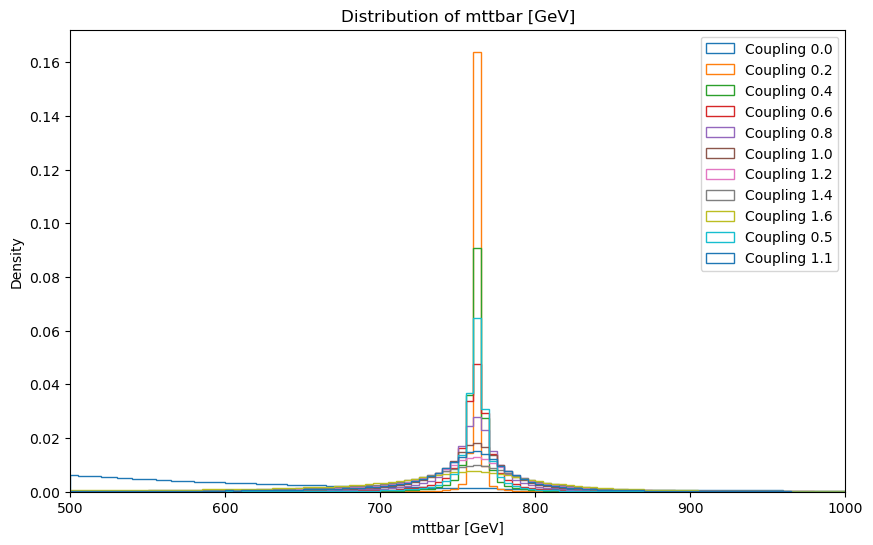

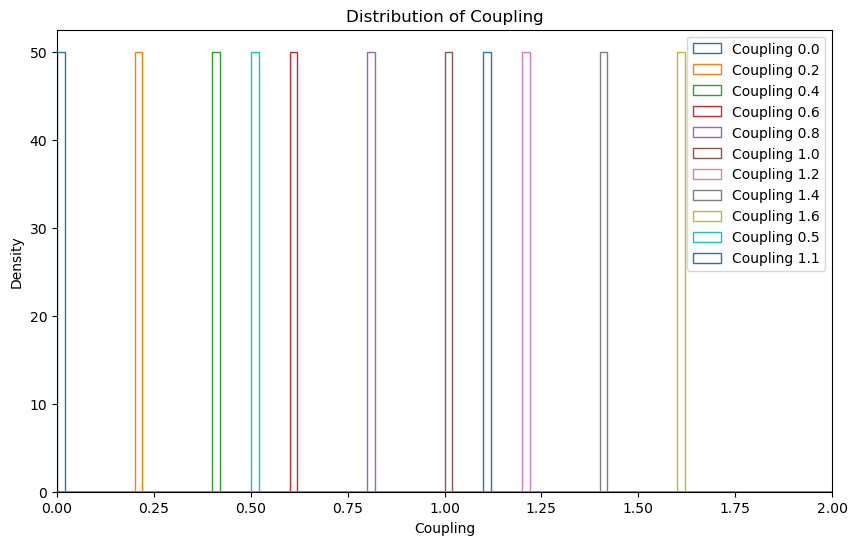

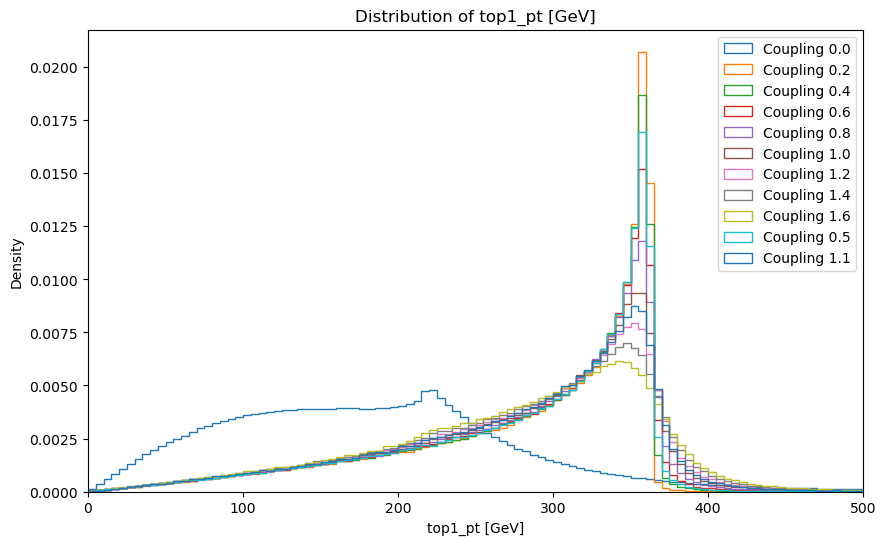

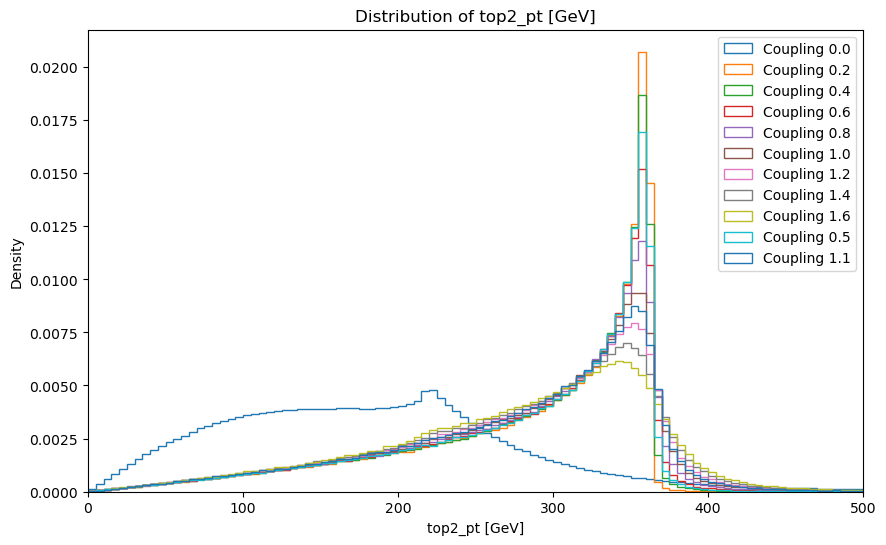

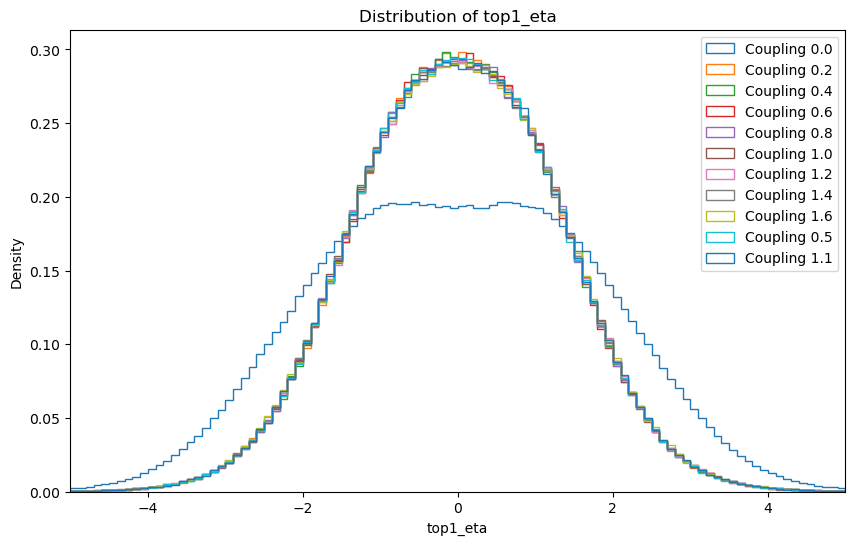

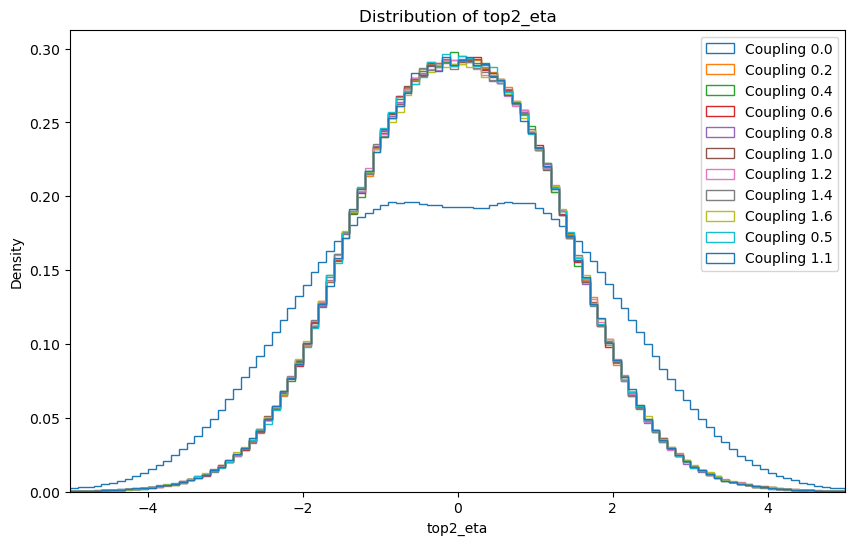

In [6]:
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], indices_per_coupling, x_range=[500,1000], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)

In [7]:
X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
X = rfn.structured_to_unstructured(X)
X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:]
X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
coupling_values_for_training = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
X_couplings[background_indices] = np.random.choice(coupling_values_for_training, size=(len(background_indices),1))
y_category = np.empty_like(y)
couplings_category_dict = {}
for i in range(len(coupling_values)):
    coupling = coupling_values[i]
    indices = indices_per_coupling[coupling]
    y_category[indices] = i
    couplings_category_dict[coupling_values[i]] = i

y_category

# Form the data
X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1)], axis=1)
y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X shape =  (8856072, 8)
X example =  [ 9.6104195e+01  3.4631250e+00 -6.7409486e-01  9.6104195e+01
  4.6246383e-01  2.4674978e+00  7.0887292e+02  2.0000000e-01]
y shape =  (8856072, 2)
y example =  [0. 0.]


In [8]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [9]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', LogScaler(), [6]),
    ('coupling', MinMaxScaler(), [7])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X)
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (8856072, 6)
X example after scaling =  [4.5654435  4.5654435  2.2740333  0.30347833 6.563678   0.        ]


# Separate the datasets for new observations

In [10]:
# Print the dictionary to help user steer the code
for key, values in couplings_category_dict.items():
    print(key, ' --> ', values)

0.0  -->  0
0.2  -->  1
0.4  -->  2
0.6  -->  3
0.8  -->  4
1.0  -->  5
1.2  -->  6
1.4  -->  7
1.6  -->  8
0.5  -->  9
1.1  -->  10


In [11]:
coupling_0p5_indices = np.argwhere(y[:,1]==9)
coupling_1p1_indices = np.argwhere(y[:,1]==10)

X_inference_1 = X[coupling_0p5_indices]
X_inference_2 = X[coupling_1p1_indices]
y_inference_1 = y[coupling_0p5_indices]
y_inference_2 = y[coupling_1p1_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)

In [12]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (6333295, 6)
Validation set size =  (791662, 6)
Test set size =  (791662, 6)


In [13]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [23]:
import torch.nn as nn
# Define the Classifier
class Classifier(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(Classifier, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.BatchNorm1d(hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim//2, 1),
        )

    def forward(self, X):
        logits = self.net(X)
        return logits

In [24]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor,
                              y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,
                              y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor,
                              y_test_tensor)

# Create DataLoader objects for training, validation, and testing in batches
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True, num_workers=8, persistent_workers=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=2048, shuffle=False, num_workers=8, persistent_workers=True, drop_last=True)
test_loader  = DataLoader(test_dataset, batch_size=2048, shuffle=False, num_workers=8)

In [25]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
model = Classifier(x_dim = X.shape[1] - 1, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCELoss(reduction='none')
optimizer_parametric = optim.AdamW(model.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler = ReduceLROnPlateau(optimizer_parametric, "min", patience=5, factor=0.8)

NN: Using parametric model with theta dimension = 1


In [26]:
# Training loop on mini-batches with loss stored for plotting
train_losses = []
val_losses = []
num_epochs = 150

model.to(device)

for epoch in range(num_epochs):
    model.train()
    # run over batches of data
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer_parametric.zero_grad()
        inputs_device = inputs.to(device)
        targets_device = targets[:,0].to(device)
        outputs = model(inputs_device)
        outputs = torch.sigmoid(outputs)
        # Weight according to number of S/B events
        n_signal = torch.sum(targets_device==1).item()
        n_background = torch.sum(targets_device==0).item()
        weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))

        loss = criterion(outputs.squeeze(), targets_device) * weights
        loss = torch.sum(loss)/len(loss)
        loss.backward()
        optimizer_parametric.step()
        running_loss += loss.item()

    # compute avergae loss over all batches
    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation step
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            outputs = model(inputs_device)
            outputs = torch.sigmoid(outputs)
            # Weight according to number of S/B events
            n_signal = torch.sum(targets_device==1).item()
            n_background = torch.sum(targets_device==0).item()
            weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))
            loss = criterion(outputs.squeeze(), targets_device) * weights
            loss = torch.sum(loss)/len(loss)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    scheduler.step(val_loss)

    print(f"Learning rate: {scheduler.get_last_lr()[0]}")
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

Learning rate: 0.0002
Epoch 1/150, Train Loss: 0.1652, Val Loss: 0.1492
Learning rate: 0.0002
Epoch 2/150, Train Loss: 0.1503, Val Loss: 0.1474
Learning rate: 0.0002
Epoch 3/150, Train Loss: 0.1490, Val Loss: 0.1471
Learning rate: 0.0002
Epoch 4/150, Train Loss: 0.1485, Val Loss: 0.1466
Learning rate: 0.0002
Epoch 5/150, Train Loss: 0.1483, Val Loss: 0.1469
Learning rate: 0.0002
Epoch 6/150, Train Loss: 0.1480, Val Loss: 0.1465
Learning rate: 0.0002
Epoch 7/150, Train Loss: 0.1478, Val Loss: 0.1460
Learning rate: 0.0002
Epoch 8/150, Train Loss: 0.1477, Val Loss: 0.1457
Learning rate: 0.0002
Epoch 9/150, Train Loss: 0.1476, Val Loss: 0.1504
Learning rate: 0.0002
Epoch 10/150, Train Loss: 0.1475, Val Loss: 0.1507
Learning rate: 0.0002
Epoch 11/150, Train Loss: 0.1474, Val Loss: 0.1462
Learning rate: 0.0002
Epoch 12/150, Train Loss: 0.1474, Val Loss: 0.1461
Learning rate: 0.0002
Epoch 13/150, Train Loss: 0.1473, Val Loss: 0.1459
Learning rate: 0.0002
Epoch 14/150, Train Loss: 0.1473, Val 

In [27]:
save_model = True
if save_model:
    print("Saving model...")
    torch.save(model.state_dict(), 'pNN_ttbar.pth')

Saving model...


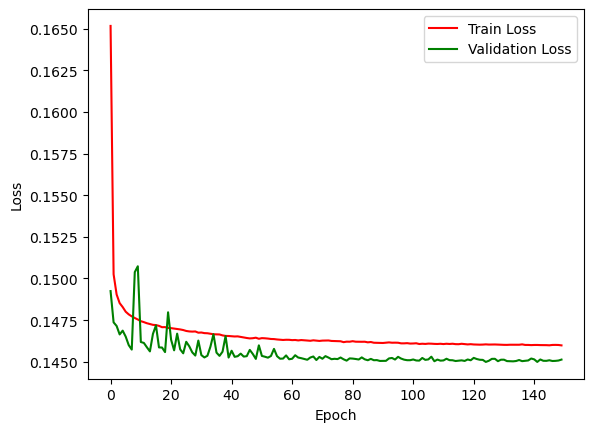

In [28]:
# Plot loss function for training and validation sets
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(val_losses, label='Validation Loss', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Loss', 'Validation Loss'])
plt.show()

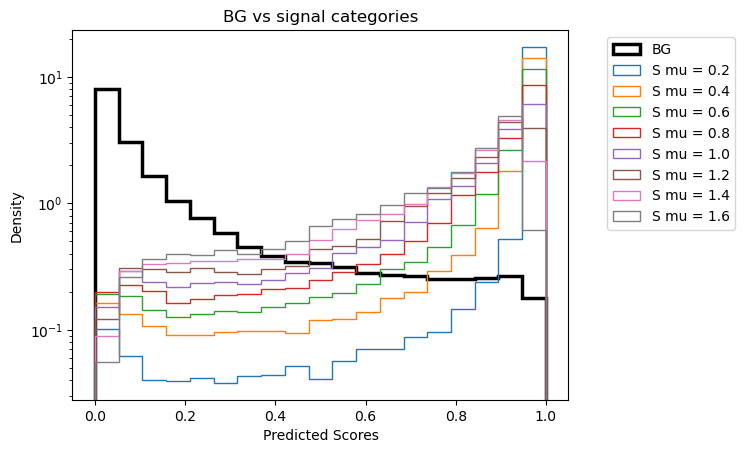

In [29]:
load_model = False
if load_model:
    eval_model = Classifier(x_dim = X.shape[1] - 1, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('pNN_ttbar.pth', weights_only=True))
else:
    eval_model = model


eval_model.to('cpu')
eval_model.eval()
y_pred = torch.sigmoid(eval_model(X_test_tensor).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test[:,0]
category_label = y_test[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = set(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

x_bins = np.linspace(0,1,20)

plt.hist(true_bkg, bins=x_bins, histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=x_bins, histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

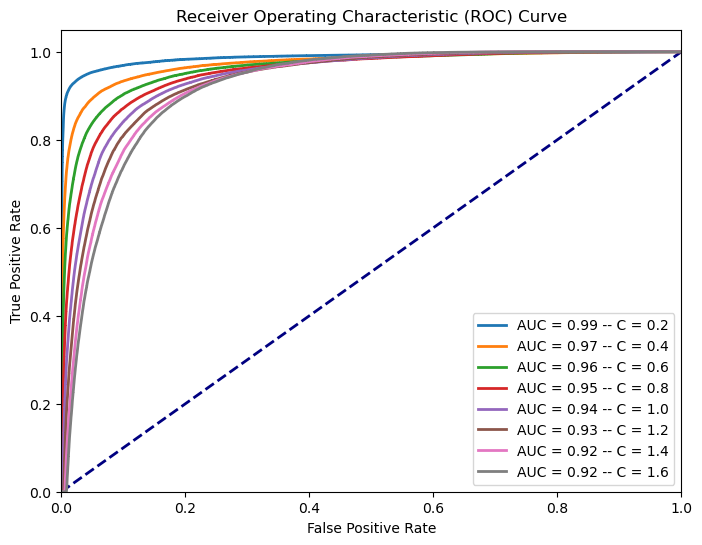

In [30]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

[[ 5.6989613   5.6989613  -0.5287297   0.31135502  6.6384215   0.21428572]]
Scanning theteta = 0.1 -0.07142857611179351
Scanning theteta = 0.21724137931034482 0.012315268249347283
Scanning theteta = 0.33448275862068966 0.0960591126104881
Scanning theteta = 0.4517241379310345 0.1798029569716289
Scanning theteta = 0.5689655172413793 0.26354680133276975
Scanning theteta = 0.6862068965517241 0.3472906456939105
Scanning theteta = 0.8034482758620689 0.43103449005505134
Scanning theteta = 0.9206896551724137 0.5147783344161921
Scanning theteta = 1.0379310344827586 0.5985221787773329
Scanning theteta = 1.1551724137931034 0.6822660231384737
Scanning theteta = 1.2724137931034483 0.7660098674996145
Scanning theteta = 1.389655172413793 0.8497537118607554
Scanning theteta = 1.506896551724138 0.9334975562218961
Scanning theteta = 1.6241379310344828 1.017241400583037
Scanning theteta = 1.7413793103448276 1.100985244944178
Scanning theteta = 1.8586206896551725 1.1847290893053186
Scanning theteta = 1.97

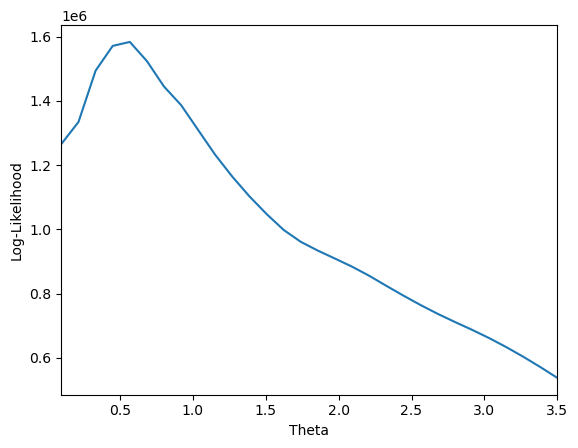

MLE estimate for theta: 0.5689655172413793


In [31]:
def ratio(x_obs, theta):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio(X_obs, thetas)
    return torch.sum(torch.log(r_vals))



new_data =  X_inference_1
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-1] # Remove coupling column
new_X = torch.tensor(new_data, requires_grad=False)


log_likelihoods = []
x = np.linspace(0.1,3.5,30)
for ix in x:
    theta_transformed = scaler["coupling"].transform([[ix]])[0,0]
    print("Scanning theteta =", ix, theta_transformed)
    theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
    llh = log_likelihood(theta_tensor, new_X)
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmax(log_likelihoods)
theta_mle = x[np.argmax(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

[[ 5.855247    5.855247   -0.5373241  -0.16466045  6.6428514   0.6428572 ]]
Scanning theteta = 0.0 -0.1428571492433548
Scanning theteta = 0.08620689655172414 -0.08128079309545713
Scanning theteta = 0.1724137931034483 -0.01970443694755948
Scanning theteta = 0.25862068965517243 0.04187191920033817
Scanning theteta = 0.3448275862068966 0.10344827534823584
Scanning theteta = 0.4310344827586207 0.1650246314961335
Scanning theteta = 0.5172413793103449 0.22660098764403114
Scanning theteta = 0.603448275862069 0.2881773437919288
Scanning theteta = 0.6896551724137931 0.34975369993982647
Scanning theteta = 0.7758620689655173 0.4113300560877242
Scanning theteta = 0.8620689655172414 0.4729064122356218
Scanning theteta = 0.9482758620689655 0.5344827683835194
Scanning theteta = 1.0344827586206897 0.5960591245314171
Scanning theteta = 1.120689655172414 0.6576354806793148
Scanning theteta = 1.206896551724138 0.7192118368272123
Scanning theteta = 1.293103448275862 0.78078819297511
Scanning theteta = 1.3

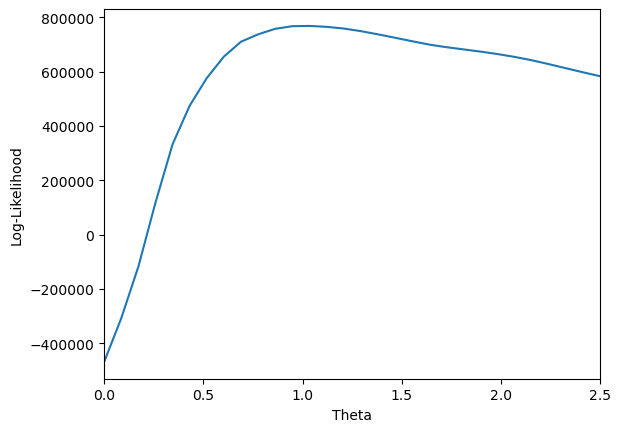

MLE estimate for theta: 1.0344827586206897


In [32]:
new_data =  X_inference_2
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-1] # Remove coupling column
new_X = torch.tensor(new_data, requires_grad=False)


log_likelihoods = []
x = np.linspace(0,2.5,30)
for ix in x:
    theta_transformed = scaler["coupling"].transform([[ix]])[0,0]
    print("Scanning theteta =", ix, theta_transformed)
    theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
    llh = log_likelihood(theta_tensor, new_X)
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmax(log_likelihoods)
theta_mle = x[np.argmax(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)